In [3]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.config import Config
from aml.features import INPUT_COLUMNS, WINDOWS, build_features, feature_columns
from aml.io import load_accounts
from aml.metrics import univariate_screen
from aml.plotting import LAUNDERING, MUTED, NORMAL, save, set_style

config = Config()
paths = config.paths
FIG = paths.figures_dir
set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:

tx = pd.read_parquet(paths.processed_dir / "transactions.parquet", columns=INPUT_COLUMNS + ["payment_format"])
accounts = load_accounts(paths.accounts_csv)
print(f"{len(tx):,} cleaned transactions | {len(accounts):,} accounts")
tx[["tx_id", "timestamp", "from_node", "to_node", "amount_paid_usd", "payment_format", "split", "is_laundering"]].head()

5,077,237 cleaned transactions | 518,581 accounts


,tx_id,timestamp,from_node,to_node,amount_paid_usd,payment_format,split,is_laundering
0,2,2022-09-01,3209_8000F4670,3209_8000F4670,"14,675.5700",Reinvestment,train,0
1,17,2022-09-01,1420_8005DFEB0,1420_8005DFEB0,897.3700,Reinvestment,train,0
2,158,2022-09-01,10_8000F6850,10_8000F6850,"99,986.9400",Reinvestment,train,0
3,218,2022-09-01,12_8001167D0,12_8001167D0,16.0800,Reinvestment,train,0
4,281,2022-09-01,1_8001364A0,1_8001364A0,10.3000,Reinvestment,train,0


In [5]:
counts = tx.loc[tx["is_self_loop"] == 0, "from_idx"].value_counts()
example_idx = counts[counts.between(6, 8)].index[0]
example = tx[tx["from_idx"] == example_idx].copy()

example_feats = build_features(example)   # only this account's own rows are needed for its out-history
cols = ["snd_out_cnt_all", "snd_out_distinct_cp_all", "snd_out_mins_since_last", "pair_prior_cnt"]
example[["timestamp", "to_node", "amount_paid_usd", "is_self_loop"]].join(example_feats[cols])

17:45:42 | INFO | aml.features | Building histories from 8 non-self transactions
17:45:42 | INFO | aml.features | Querying sender and receiver histories in chunks of 500,000 rows
17:45:42 | INFO | aml.features | Built 70 features for 9 transactions


,timestamp,to_node,amount_paid_usd,is_self_loop,snd_out_cnt_all,snd_out_distinct_cp_all,snd_out_mins_since_last,pair_prior_cnt
93,2022-09-01 00:00:00,908_80059E940,"54,108.6400",0,0,0.0000,NaN,0
21914,2022-09-01 00:02:00,908_80059E940,"13,547.0700",0,1,1.0000,2.0000,1
142804,2022-09-01 00:13:00,1_8043D2EE0,"86,419.7300",0,2,1.0000,11.0000,0
219308,2022-09-01 00:20:00,1_8043D2EE0,"43,281.5800",0,3,2.0000,7.0000,1
240107,2022-09-01 00:22:00,908_80059E940,"308,027.8400",0,4,2.0000,2.0000,2
883870,2022-09-01 17:07:00,1467_8003BD2B0,"3,260,699.8300",1,5,2.0000,"1,005.0000",0
1733924,2022-09-02 19:35:00,11813_8012A9EC0,"140,826.0200",0,5,2.0000,"2,593.0000",0
1744435,2022-09-02 19:56:00,11813_8012A9EC0,"189,015.0500",0,6,3.0000,21.0000,1
2610197,2022-09-05 15:56:00,1601_8003C0E20,"2,022.9100",0,7,3.0000,"4,080.0000",0


## Building all the features

In [7]:
feats = build_features(tx.drop(columns="payment_format"), accounts)
FEATURES = feature_columns(feats)
print(f"{len(FEATURES)} features | {feats.memory_usage(deep=True).sum() / 1e9:.2f} GB")

17:45:42 | INFO | aml.features | Building histories from 4,486,418 non-self transactions
17:45:45 | INFO | aml.features | Querying sender and receiver histories in chunks of 500,000 rows
17:48:08 | INFO | aml.features | Entity info joined (0=Corporation, 1=Country, 2=Direct, 3=Individual, 4=Partnership, 5=Sole Proprietorship); 0.00% of senders not in accounts file
17:48:08 | INFO | aml.features | Built 75 features for 5,077,237 transactions


75 features | 1.51 GB


In [8]:
cutoff = pd.Timestamp("2022-09-04")
early = build_features(tx.loc[tx["timestamp"] < cutoff, INPUT_COLUMNS], accounts)
same = feats.loc[early.index, FEATURES].equals(early[FEATURES])
print(f"Rows compared: {len(early):,} | identical: {same}")
assert same, "Features changed when future data was removed -> leakage"

17:48:08 | INFO | aml.features | Building histories from 1,549,530 non-self transactions
17:48:09 | INFO | aml.features | Querying sender and receiver histories in chunks of 500,000 rows
17:48:32 | INFO | aml.features | Entity info joined (0=Corporation, 1=Country, 2=Direct, 3=Individual, 4=Partnership, 5=Sole Proprietorship); 0.00% of senders not in accounts file
17:48:32 | INFO | aml.features | Built 75 features for 2,076,752 transactions


Rows compared: 2,076,752 | identical: True


In [9]:
del early
# The raw transactions are no longer needed; free memory for the analysis below
tx = tx[["tx_id", "payment_format"]]

## Feature catalogue and missing values

In [10]:
def group_of(col):
    if col.startswith(("snd_entity", "rcv_entity")) or col == "same_entity":
        return "account owner (accounts file)"
    if col.startswith("pair_"):
        return "relationship between the two accounts"
    if col.startswith(("snd_", "rcv_")) and "_self_" not in col:
        return f"{col.split('_')[0]} history ({col.split('_')[1]})"
    return "this transaction"

catalogue = pd.Series({c: group_of(c) for c in FEATURES}, name="group")
catalogue.value_counts().rename("features").to_frame()

,features
group,
snd history (out),15
snd history (in),15
rcv history (out),15
rcv history (in),15
this transaction,8
account owner (accounts file),5
relationship between the two accounts,2


In [11]:
missing = feats[FEATURES].isna().mean().sort_values(ascending=False)
missing[missing > 0].head(12).rename("share missing").to_frame()

,share missing
rcv_out_mean_usd_1h,0.9555
snd_in_mean_usd_1h,0.9325
rcv_out_mean_usd_24h,0.6511
rcv_out_std_log_usd_all,0.5621
rcv_in_mean_usd_1h,0.5515
rcv_out_max_usd_all,0.5088
rcv_out_cp_ratio_all,0.5088
rcv_out_mean_usd_all,0.5088
rcv_out_mins_since_last,0.5088
rcv_out_mins_since_first,0.5088


## 6. Which features carry signal (train split only)



- `roc_auc`: 0.5 means no signal, 1.0 means perfect ranking.
- `pr_auc`: the more honest number for rare events. A useless feature scores the base rate
  (about 0.00075 here), so `lift` = `pr_auc / base rate` says how many times better than chance it is.

In [12]:
train = feats[feats["split"] == "train"]
screen = univariate_screen(train, FEATURES)
base_rate = screen.attrs["base_rate"]
screen["lift"] = screen["pr_auc"] / base_rate
print(f"Train base rate: {base_rate:.5f}")
screen.head(15)

Train base rate: 0.00075


,roc_auc,direction,pr_auc,lift
feature,,,,
pair_reverse_prior_cnt,0.5257,higher = riskier,0.0167,22.1038
payment_format_code,0.8809,lower = riskier,0.0049,6.5587
rcv_in_distinct_cp_all,0.5747,higher = riskier,0.0017,2.2932
amount_vs_rcv_in_mean,0.6026,higher = riskier,0.0017,2.2790
pair_prior_cnt,0.7328,lower = riskier,0.0016,2.0578
log_amount_usd,0.6704,higher = riskier,0.0015,1.9435
rcv_in_mins_since_last,0.5901,higher = riskier,0.0014,1.8803
rcv_in_cp_ratio_all,0.6076,higher = riskier,0.0012,1.6302
snd_out_cnt_24h,0.5903,lower = riskier,0.0011,1.4393


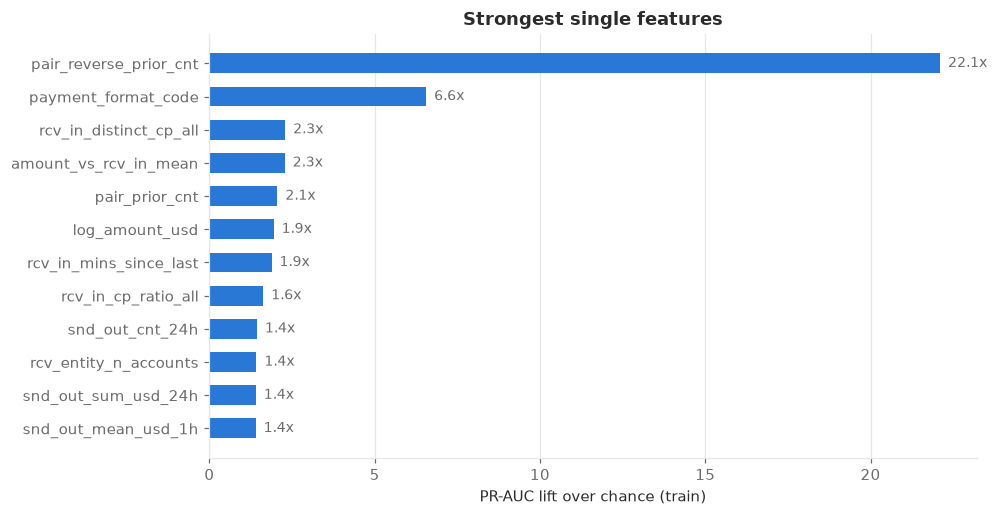

In [13]:
top = screen.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top["lift"], color=NORMAL, height=0.6)
for y, v in enumerate(top["lift"]):
    ax.text(v, y, f"  {v:.1f}x", va="center", color=MUTED, fontsize=9)
ax.set_xlabel("PR-AUC lift over chance (train)")
ax.set_title("Strongest single features")
ax.grid(axis="y", visible=False)
save(fig, FIG, "05_feature_lift")
plt.show()

In [14]:
def rate_table(mask, labels):
    g = train.groupby(np.where(mask, labels[1], labels[0]))["is_laundering"]
    t = pd.DataFrame({"transactions": g.size(), "laundering": g.sum(), "laundering_rate_%": 100 * g.mean()})
    t["share_of_all_laundering_%"] = 100 * t["laundering"] / train["is_laundering"].sum()
    return t.reindex(labels)

behaviours = {
    "Sender has paid this receiver before?": rate_table(train["pair_prior_cnt"] > 0, ["first time", "paid before"]),
    "Has the receiver ever paid the sender?": rate_table(train["pair_reverse_prior_cnt"] > 0, ["never", "yes, money flowing back"]),
    "Same owner on both sides?": rate_table(train["same_entity"] == 1, ["different owners", "same owner"]),
}
pd.concat(behaviours)

transactions  \
Sender has paid this receiver before?  first time                    1128339   
                                       paid before                   1917847   
Has the receiver ever paid the sender? never                         3044593   
                                       yes, money flowing back          1593   
Same owner on both sides?              different owners              2458235   
                                       same owner                     587951   

                                                                laundering  \
Sender has paid this receiver before?  first time                     1867   
                                       paid before                     429   
Has the receiver ever paid the sender? never                          2177   
                                       yes, money flowing back         119   
Same owner on both sides?              different owners               2279   
                                       same owner                       17   

                                                                laundering_rate_%  \
Sender has paid this receiver before?  first time                          0.1655   
                                       paid before                         0.0224   
Has the receiver ever paid the sender? never                               0.0715   
                                       yes, money flowing back             7.4702   
Same owner on both sides?              different owners                    0.0927   
                                       same owner                          0.0029   

                                                                share_of_all_laundering_%  
Sender has paid this receiver before?  first time                                 81.3153  
                                       paid before                                18.6847  
Has the receiver ever paid the sender? never                                      94.8171  
                                       yes, money flowing back                     5.1829  
Same owner on both sides?              different owners                           99.2596  
                                       same owner                                  0.7404

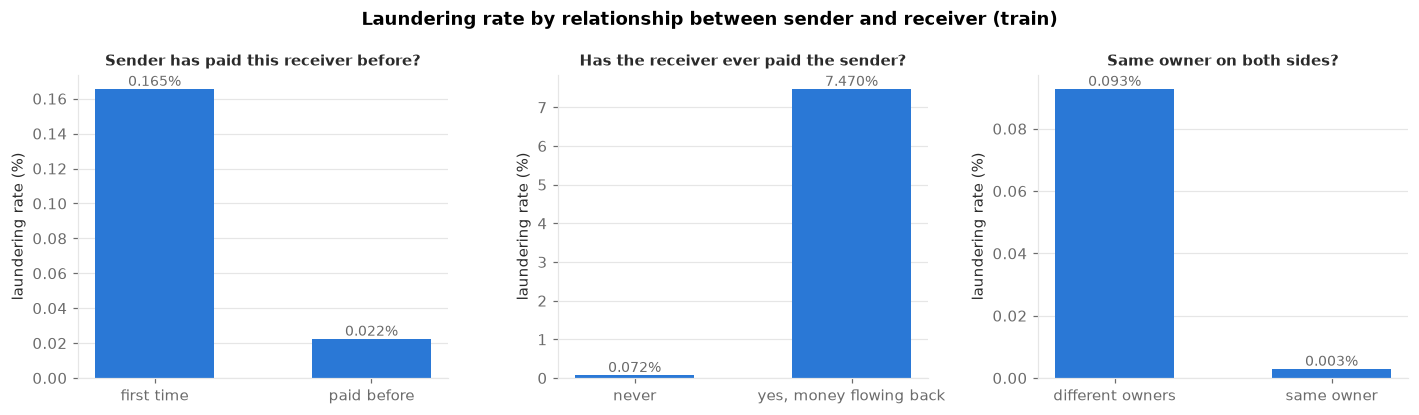

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (title, t) in zip(axes, behaviours.items()):
    rates = t["laundering_rate_%"]
    ax.bar(rates.index, rates.values, color=NORMAL, width=0.55)
    for x, v in enumerate(rates.values):
        ax.text(x, v, f"{v:.3f}%", ha="center", va="bottom", color=MUTED, fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("laundering rate (%)")
    ax.grid(axis="x", visible=False)
fig.suptitle("Laundering rate by relationship between sender and receiver (train)", fontweight="bold")
plt.tight_layout()
save(fig, FIG, "06_relationship_signals")
plt.show()

In [16]:
import json
format_codes = json.loads((paths.processed_dir / "payment_formats.json").read_text())
ach = train[train["payment_format_code"] == format_codes["ACH"]]
ach_screen = univariate_screen(ach, [c for c in FEATURES if c != "payment_format_code"])
ach_screen["lift"] = ach_screen["pr_auc"] / ach_screen.attrs["base_rate"]
print(f"ACH train rows: {len(ach):,} | ACH base rate: {ach_screen.attrs['base_rate']:.5f}")
ach_screen.sort_values("roc_auc", ascending=False).head(12)

ACH train rows: 338,575 | ACH base rate: 0.00562


,roc_auc,direction,pr_auc,lift
feature,,,,
pair_prior_cnt,0.7450,lower = riskier,0.0112,1.9863
snd_out_cnt_1h,0.7067,lower = riskier,0.0097,1.7254
snd_out_sum_usd_1h,0.7046,lower = riskier,0.0097,1.7292
snd_out_mean_usd_1h,0.7043,lower = riskier,0.0097,1.7288
log_amount_usd,0.6847,higher = riskier,0.0090,1.6080
snd_out_cnt_24h,0.6608,lower = riskier,0.0091,1.6099
rcv_in_sum_usd_1h,0.6581,lower = riskier,0.0089,1.5739
rcv_in_mean_usd_1h,0.6578,lower = riskier,0.0088,1.5730
rcv_in_cnt_1h,0.6574,lower = riskier,0.0088,1.5583


In [17]:
sample = train[FEATURES].sample(300_000, random_state=0)
corr = sample.corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().rename("abs_spearman").sort_values(ascending=False)
print(f"Feature pairs with |rho| >= 0.95: {(pairs >= 0.95).sum()} of {len(pairs)}")
pairs.head(12).to_frame()

Feature pairs with |rho| >= 0.95: 21 of 2775


,,abs_spearman
rcv_out_cnt_1h,rcv_out_sum_usd_1h,0.9995
snd_in_cnt_1h,snd_in_sum_usd_1h,0.9991
rcv_out_sum_usd_1h,rcv_out_mean_usd_1h,0.9830
rcv_in_sum_usd_1h,rcv_in_mean_usd_1h,0.9828
snd_out_sum_usd_all,snd_out_max_usd_all,0.9820
rcv_out_cnt_all,rcv_out_distinct_cp_all,0.9806
snd_out_sum_usd_1h,snd_out_mean_usd_1h,0.9776
rcv_out_cnt_24h,rcv_out_sum_usd_24h,0.9748
rcv_out_sum_usd_all,rcv_out_max_usd_all,0.9728
snd_out_mean_usd_all,snd_out_max_usd_all,0.9681
